# 01 — Setup and Dataset Exploration
**Score-Informed Dynamic Marking Adherence Evaluation — FYP Pipeline (fyp_try2)**

This notebook:
1. Clones the **(n)ASAP dataset** (CPJKU/asap-dataset) into the Colab session
2. Loads and inspects `metadata.csv` (17 columns, ~1066 performance rows)
3. Filters out performances with unreliable note-level alignment (`robust_note_alignment == 1`) — *Methodology Problem 8*
4. Explores the performances-per-piece distribution — *Methodology Problem 1*
5. **Previews** (but does not apply) the soft cap of 10 performances per piece
6. Saves the cleaned (alignment-filtered, **uncapped**) metadata to `fyp_try2/` for later notebooks

> **Where the soft cap is applied (updated):** per the methodology, the cap is applied at
> **dataset assembly (notebook 04)** — *after* extraction and synthetic generation, not here.
> This notebook therefore saves all robust-aligned performances. The synthetic-count formula
> in notebook 03a still uses the **capped** figure `min(real_count, 10)` when deciding how
> many synthetics each piece receives, so the ~30% synthetic share stays consistent with
> the post-cap real counts (Problems 1 + 3 interact — see notebook 03a).

> **Dataset note:** this project deliberately uses the CPJKU **(n)ASAP** repository, whose
> `metadata.csv` has 17 columns including `robust_note_alignment`. A flag called
> `score_and_performance_aligned` does **not** exist as a CSV column — that information lives
> in `asap_annotations.json` — so it is not used here.


> **Local version.** This notebook was converted from Google Colab to run on a local machine.
> Changes: no `!pip install` (dependencies come from `requirements.txt` / the project venv),
> no Google Drive mount, and all paths are relative to the project folder — so the same
> notebook runs on Windows, macOS or Linux without edits.

## 1. Environment and dataset setup

In [3]:
# Environment check - run this first
# Replaces the Colab "!pip install music21 pretty_midi -q" cell.
# If anything below fails, the venv is not active or deps are missing:
#     pip install -r requirements.txt
import sys, importlib

print('python     :', sys.version.split()[0])
print('executable :', sys.executable)   # should point inside .venv

for pkg in ['numpy', 'pandas', 'matplotlib', 'music21', 'pretty_midi']:
    try:
        m = importlib.import_module(pkg)
        print(f'{pkg:<12}: {getattr(m, "__version__", "ok")}')
    except ImportError as e:
        print(f'{pkg:<12}: MISSING  ->  pip install -r requirements.txt   ({e})')


python     : 3.14.3
executable : d:\Projects\fyp\.venv\Scripts\python.exe
numpy       : 2.5.3
pandas      : 3.0.6
matplotlib  : 3.11.2
music21     : 10.5.0
pretty_midi : 0.2.11.post0


In [ ]:
# Setup: project paths + one-time dataset clone (local, no Drive)
import os, sys, json, random, copy, time, shutil, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Project layout ---------------------------------------------------------
# Resolve the project root whether the notebook is opened from the project
# folder itself or from the notebooks/ subfolder.
PROJECT = Path.cwd().resolve()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent

BASE      = PROJECT / 'fyp_try2'                 # outputs (was MyDrive/fyp_try2)
ASAP_ROOT = PROJECT / 'data' / 'asap-dataset'    # dataset (was /content/asap-dataset)

BASE.mkdir(parents=True, exist_ok=True)
ASAP_ROOT.parent.mkdir(parents=True, exist_ok=True)

# --- One-time clone of the (n)ASAP dataset ----------------------------------
# Kept on disk, so this only downloads once - unlike Colab, where every new
# session re-cloned it.
if not (ASAP_ROOT / 'metadata.csv').exists():
    if shutil.which('git') is None:
        raise RuntimeError(
            'git was not found on PATH. Install Git (https://git-scm.com/downloads), '
            'reopen the terminal, restart the kernel, and re-run this cell.'
        )
    print('Cloning (n)ASAP dataset (shallow clone, a few GB - this takes a few minutes)...')
    subprocess.run(
        ['git', 'clone', '--depth', '1',
         'https://github.com/CPJKU/asap-dataset.git', str(ASAP_ROOT)],
        check=True,
    )
    print('Clone finished.')
else:
    print('ASAP dataset already on disk - skipping clone.')

print('Project root :', PROJECT)
print('Output base  :', BASE)
print('ASAP root    :', ASAP_ROOT, '| metadata.csv present:', (ASAP_ROOT / 'metadata.csv').exists())


ASAP dataset already on disk - skipping clone.
Project root : D:\Projects\fyp
Output base  : D:\Projects\fyp\fyp_try2
ASAP root    : D:\Projects\fyp\data\asap-dataset | metadata.csv present: True


## 2. Load and inspect `metadata.csv`

In [ ]:
# Load metadata and confirm structure
meta = pd.read_csv(ASAP_ROOT / 'metadata.csv')
print('shape:', meta.shape)
print('columns:', list(meta.columns))
assert 'robust_note_alignment' in meta.columns, \
    'robust_note_alignment missing - is this really the CPJKU (n)ASAP clone?'
meta.head(3)

shape: (1066, 17)
columns: ['composer', 'title', 'folder', 'xml_score', 'midi_score', 'midi_performance', 'performance_annotations', 'midi_score_annotations', 'maestro_midi_performance', 'maestro_audio_performance', 'start', 'end', 'audio_performance', 'robust_note_alignment', 'note_alignments', 'parangonada_data_folder', 'match_file']


,composer,title,folder,xml_score,midi_score,midi_performance,performance_annotations,midi_score_annotations,maestro_midi_performance,maestro_audio_performance,start,end,audio_performance,robust_note_alignment,note_alignments,parangonada_data_folder,match_file
0,Bach,Fugue_bwv_846,Bach/Fugue/bwv_846,Bach/Fugue/bwv_846/xml_score.musicxml,Bach/Fugue/bwv_846/midi_score.mid,Bach/Fugue/bwv_846/Shi05M.mid,Bach/Fugue/bwv_846/Shi05M_annotations.txt,Bach/Fugue/bwv_846/midi_score_annotations.txt,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,{maestro}/2006/MIDI-Unprocessed_19_R1_2006_01-...,144.567708,NaN,Bach/Fugue/bwv_846/Shi05M.wav,1.0,Bach/Fugue/bwv_846/Shi05M_note_alignments/note...,Bach/Fugue/bwv_846/Shi05M_note_alignments/para...,Bach/Fugue/bwv_846/Shi05M.match
1,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Denisova06M.mid,Bach/Fugue/bwv_848/Denisova06M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,{maestro}/2008/MIDI-Unprocessed_02_R1_2008_01-...,69.317708,NaN,Bach/Fugue/bwv_848/Denisova06M.wav,1.0,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M_note_alignments...,Bach/Fugue/bwv_848/Denisova06M.match
2,Bach,Fugue_bwv_848,Bach/Fugue/bwv_848,Bach/Fugue/bwv_848/xml_score.musicxml,Bach/Fugue/bwv_848/midi_score.mid,Bach/Fugue/bwv_848/Lee01M.mid,Bach/Fugue/bwv_848/Lee01M_annotations.txt,Bach/Fugue/bwv_848/midi_score_annotations.txt,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,{maestro}/2011/MIDI-Unprocessed_08_R1_2011_MID...,74.795573,NaN,Bach/Fugue/bwv_848/Lee01M.wav,1.0,Bach/Fugue/bwv_848/Lee01M_note_alignments/note...,Bach/Fugue/bwv_848/Lee01M_note_alignments/para...,Bach/Fugue/bwv_848/Lee01M.match


In [6]:
# Quick overview
print('Unique pieces      :', meta['folder'].nunique())
print('Total performances :', len(meta))
print('Composers          :', meta['composer'].nunique())
print()
print(meta['composer'].value_counts())

Unique pieces      : 242
Total performances : 1066
Composers          : 16

composer
Chopin          289
Beethoven       270
Bach            169
Liszt           121
Schubert         62
Haydn            44
Schumann         28
Ravel            22
Mozart           16
Scriabin         13
Balakirev        10
Prokofiev         8
Rachmaninoff      8
Debussy           3
Glinka            2
Brahms            1
Name: count, dtype: int64


## 3. Filter by alignment reliability (Problem 8)

In [7]:
# Keep only robust note-level alignments
n_before = len(meta)
clean = meta[meta['robust_note_alignment'] == 1].copy()
print(f'{n_before} -> {len(clean)} performances '
      f'({n_before - len(clean)} dropped for unreliable alignment)')
print('Pieces remaining:', clean["folder"].nunique())

1066 -> 834 performances (232 dropped for unreliable alignment)
Pieces remaining: 187


## 4. Performances-per-piece distribution (Problem 1)
A few famous pieces have 20+ recorded performances while most have 1-3.
Left unaddressed this would bias the classifier toward a handful of
frequently-performed Romantic-era pieces.

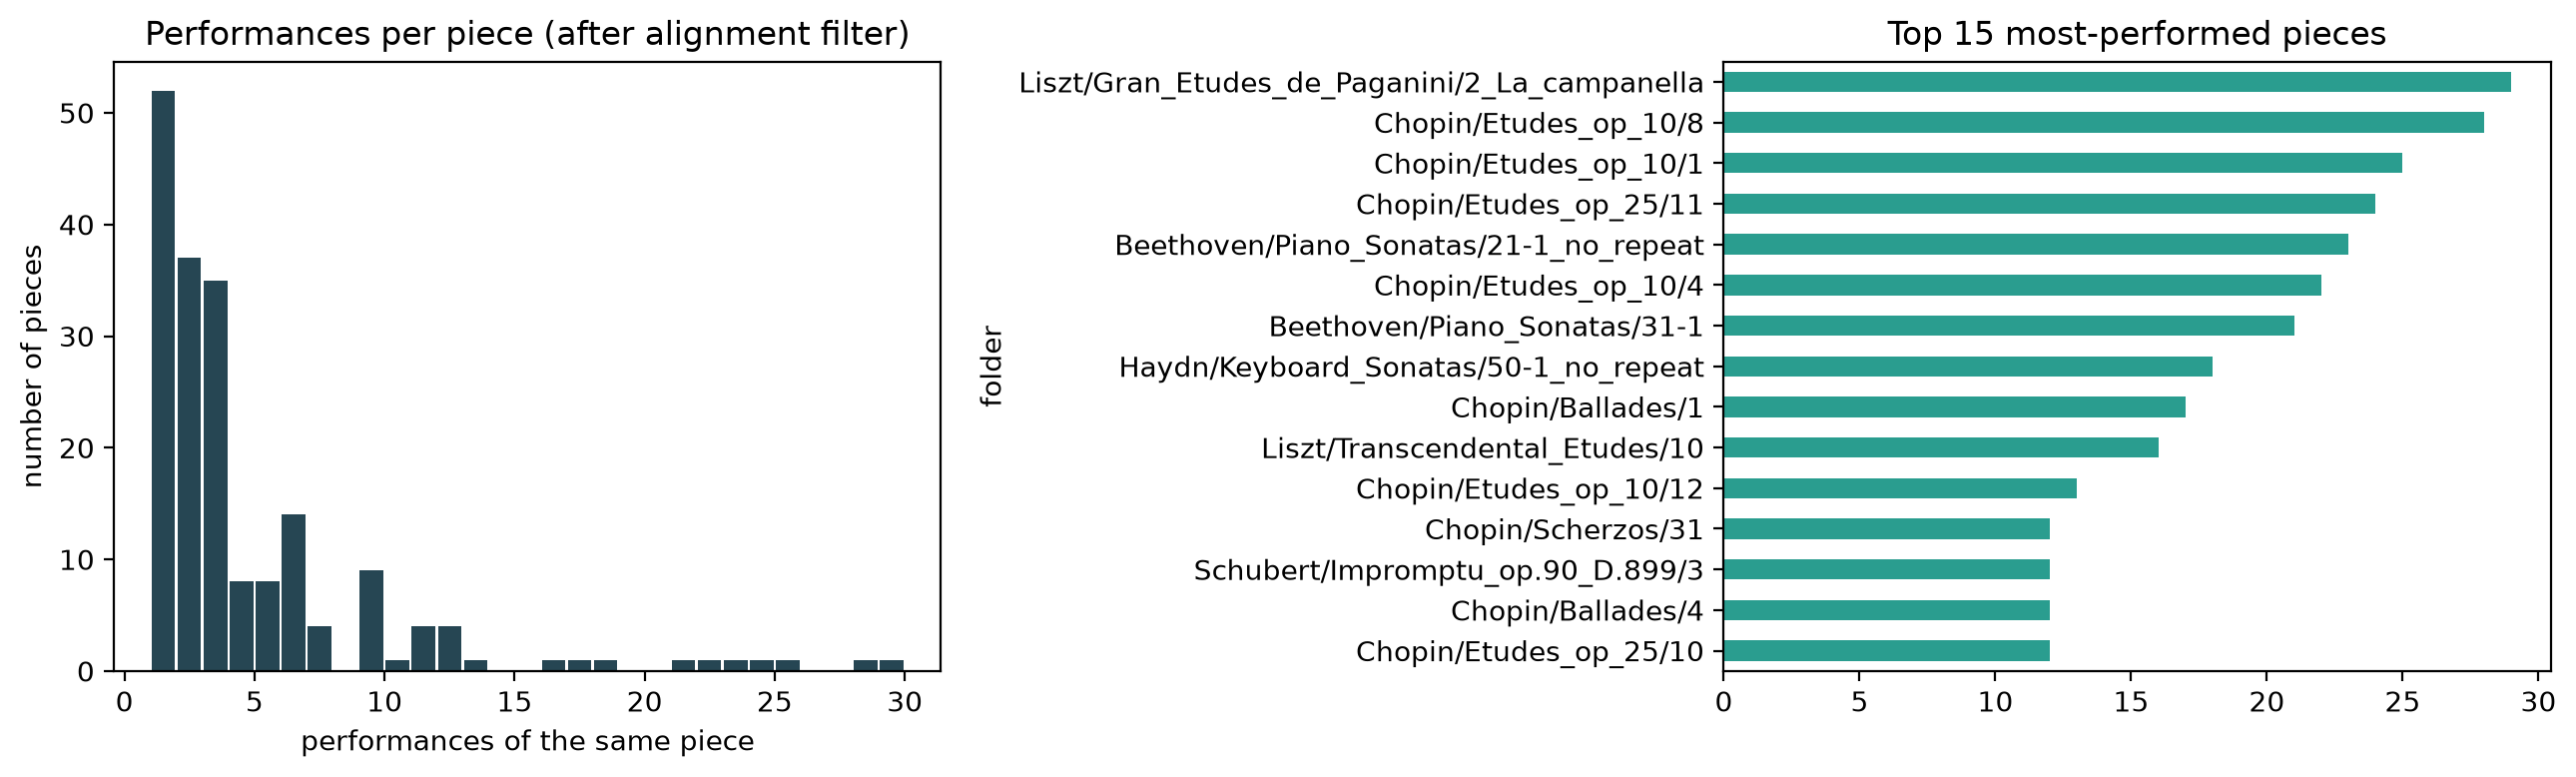

19 pieces have more than 10 performances (10.2% of pieces)


In [8]:
# Histogram + top pieces
per_piece = clean.groupby('folder').size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(per_piece, bins=range(1, per_piece.max() + 2), color='#264653', rwidth=0.9)
axes[0].set_xlabel('performances of the same piece'); axes[0].set_ylabel('number of pieces')
axes[0].set_title('Performances per piece (after alignment filter)')
per_piece.head(15).plot.barh(ax=axes[1], color='#2a9d8f')
axes[1].invert_yaxis(); axes[1].set_title('Top 15 most-performed pieces')
plt.tight_layout(); plt.show()

n_over = (per_piece > 10).sum()
print(f'{n_over} pieces have more than 10 performances '
      f'({100 * n_over / len(per_piece):.1f}% of pieces)')

## 5. Preview of the soft cap (applied later, at assembly)
Shows what the cap of 10 per piece **will** remove at notebook 04, without removing
anything now. Extraction (02) and synthetic generation (03a) run on the full
robust-aligned set, exactly as the methodology specifies.

Now: 834 performances | After cap at assembly: 696 (138 rows will be trimmed from 19 over-represented pieces)


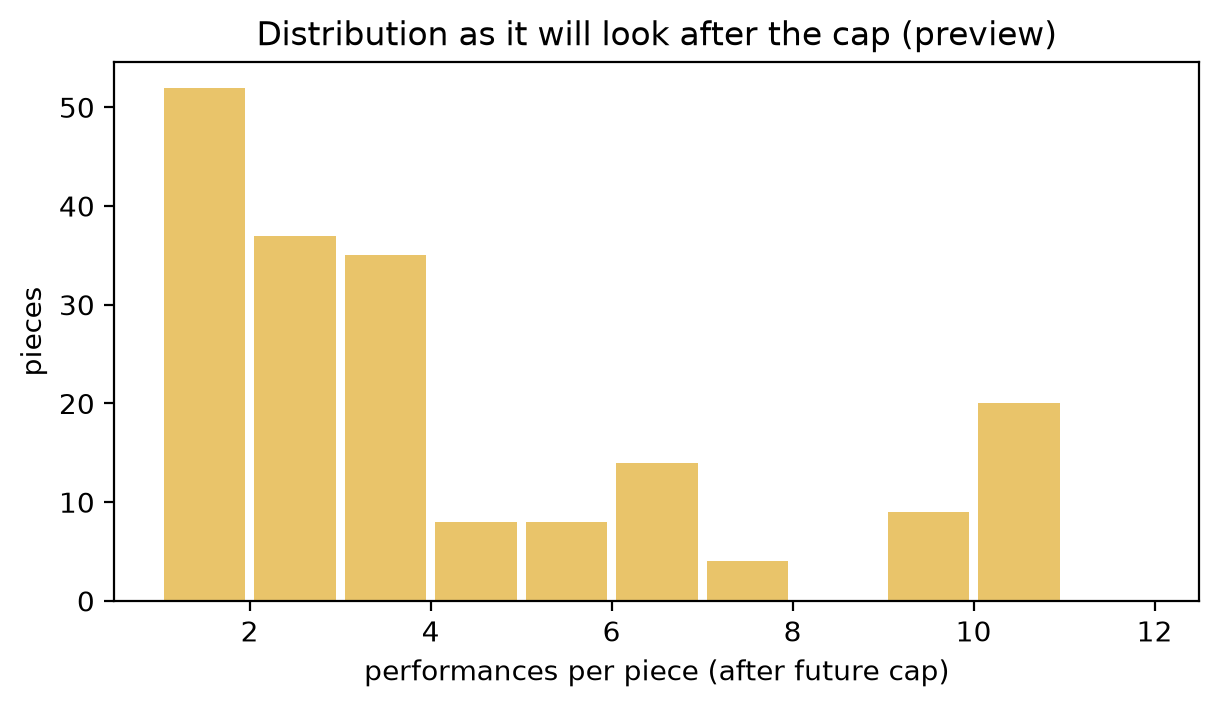

In [9]:
# Preview only - nothing is removed here
CAP = 10
would_keep = per_piece.clip(upper=CAP)
print(f'Now: {len(clean)} performances | After cap at assembly: {int(would_keep.sum())} '
      f'({len(clean) - int(would_keep.sum())} rows will be trimmed from '
      f'{(per_piece > CAP).sum()} over-represented pieces)')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(would_keep, bins=range(1, CAP + 3), color='#e9c46a', rwidth=0.9)
ax.set_xlabel('performances per piece (after future cap)'); ax.set_ylabel('pieces')
ax.set_title('Distribution as it will look after the cap (preview)'); plt.show()

## 6. Save cleaned (uncapped) metadata to `fyp_try2/`

In [10]:
# Save for later notebooks
out_path = BASE / 'cleaned_metadata.csv'
clean.to_csv(out_path, index=False)
print(f'Saved {len(clean)} rows ({clean["folder"].nunique()} pieces) to {out_path}')

provenance = {
    'source': 'CPJKU/asap-dataset (n)ASAP',
    'filter': 'robust_note_alignment == 1',
    'soft_cap': f'NOT applied here - deferred to dataset assembly (notebook 04), cap={CAP}',
    'n_performances': int(len(clean)),
    'n_pieces': int(clean['folder'].nunique()),
    'created': pd.Timestamp.now().isoformat(),
}
(BASE / 'cleaned_metadata_provenance.json').write_text(json.dumps(provenance, indent=2))
provenance

Saved 834 rows (187 pieces) to D:\Projects\fyp\fyp_try2\cleaned_metadata.csv


{'source': 'CPJKU/asap-dataset (n)ASAP',
 'filter': 'robust_note_alignment == 1',
 'soft_cap': 'NOT applied here - deferred to dataset assembly (notebook 04), cap=10',
 'n_performances': 834,
 'n_pieces': 187,
 'created': '2026-09-18T18:21:37.047849'}